# Лабораторная работа №4 — описательная статистика и статистический вывод

От выборочных статистик и нормальной модели — к анализу дневного спроса
Bike Sharing. Временной набор разделён: 2011 год служит для исследования,
2012 год — для подтверждения заранее выбранного вопроса. Все случайные
процедуры используют `RANDOM_STATE = 42`. Ячейки выполняются сверху вниз
из каталога `lab4`; интернет для локального запуска не требуется.
В Google Colab нужный CSV автоматически загружается из этого репозитория.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

RANDOM_STATE = 42
DATA_DIR = Path("data/bike-sharing/raw")
if not (DATA_DIR / "day.csv").is_file():
    try:
        import google.colab
    except ImportError as exc:
        raise FileNotFoundError(
            "Не найден data/bike-sharing/raw/day.csv. Запустите Jupyter из каталога lab4."
        ) from exc
    from hashlib import sha256
    from urllib.request import urlopen
    url = ("https://raw.githubusercontent.com/huksleva/DataScience/main/"
           "lab4/data/bike-sharing/raw/day.csv")
    try:
        with urlopen(url, timeout=60) as response:
            csv_bytes = response.read()
    except OSError as exc:
        raise RuntimeError(f"Не удалось загрузить данные Bike Sharing из {url}") from exc
    # GitHub хранит CSV с LF, а исходный архив и manifest.json — с CRLF.
    csv_bytes = csv_bytes.replace(b"\r\n", b"\n").replace(b"\n", b"\r\n")
    expected_sha256 = "a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff10cd48a874ee7ba18be"
    if sha256(csv_bytes).hexdigest() != expected_sha256:
        raise ValueError("Контрольная сумма day.csv не совпадает с manifest.json")
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    (DATA_DIR / "day.csv").write_bytes(csv_bytes)
    print("Colab: day.csv автоматически загружен и проверен.")

plt.rcParams.update({"figure.dpi": 115, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


## 1. Описательные статистики и нормальная вероятность

**Обозначения и модель.** Для $x_1,\ldots,x_n$

$$
\bar x=\frac1n\sum_{i=1}^n x_i,\qquad
s=\sqrt{\frac1{n-1}\sum_{i=1}^n(x_i-\bar x)^2}.
$$

Поэтому `ddof=1` возвращает выборочное $s$. Для нормально
распределённого срока $T$ функция распределения
$F(t)=P(T\le t)$ даёт $P(a\le T\le b)=F(b)-F(a)$.


### Ответ: описательные статистики и нормальная вероятность

Пять диаметров филамента $x_i$ (мм) считаются выборкой.
Среднее $\bar x=\sum_i x_i/n=\mathbf{1.7520}$ мм.
Стандартное отклонение переданного конечного набора с делителем $n$
равно $\mathbf{0.021354}$ мм; выборочное
$s=\sqrt{\sum_i(x_i-\bar x)^2/(n-1)}=\mathbf{0.023875}$ мм.
Для оценки неизвестной вариабельности по выборке используется `ddof=1`
(поправка Бесселя); пять чисел сами по себе не подтверждают
репрезентативность или нормальность.

Если срок службы $T\sim N(42,8^2)$ в месяцах, то
$P(20\le T\le30)=F(30)-F(20)=\mathbf{0.063827}$.
Это вероятность **при нормальной модели**, а не следствие только
среднего 42 и стандартного отклонения 8.


In [2]:
filament = np.array([1.78, 1.75, 1.72, 1.74, 1.77])
filament_mean = filament.mean()
filament_std_population = filament.std(ddof=0)
filament_std_sample = filament.std(ddof=1)
p_lifetime = stats.norm.cdf(30, loc=42, scale=8) - stats.norm.cdf(20, loc=42, scale=8)
print(f"Среднее филамента: {filament_mean:.6f} мм")
print(f"std(ddof=0): {filament_std_population:.6f} мм")
print(f"std(ddof=1): {filament_std_sample:.6f} мм")
print(f"P(20 ≤ T ≤ 30) при N(42, 8²): {p_lifetime:.6f}")


Среднее филамента: 1.752000 мм
std(ddof=0): 0.021354 мм
std(ddof=1): 0.023875 мм
P(20 ≤ T ≤ 30) при N(42, 8²): 0.063827


## 2. Доверительный интервал и двусторонний тест

**Обозначения и модель.** При неизвестной дисперсии t-интервал
среднего использует выборочное $s$:

$$
\bar x\pm t_{1-\alpha/2,n-1}\frac{s}{\sqrt n}.
$$

В задаче кампании историческое $\sigma$ считается известным и
стабильным. Для среднего $n$ дней стандартная ошибка равна
$\sigma/\sqrt n$, поэтому

$$
z=\frac{\bar x-\mu_0}{\sigma/\sqrt n},\qquad
p\text{-value}=2P(Z\ge|z|).
$$

Это тест среднего 45 дней, а не сравнение отдельного дня со
стандартным отклонением 552.


### Ответ: интервал для диаметра и тест кампании

Для $n=34$, $\bar x=1.715588$ мм и выборочного $s=0.029252$ мм
99%-й t-интервал $\bar x\pm t_{0.995,33}s/\sqrt{34}$ равен
$\mathbf{[1.701876;\ 1.729300]}$ мм. При повторении процедуры на
сопоставимых независимых выборках 99% таких интервалов покрывали бы
истинное среднее; это не вероятность уже фиксированного параметра
после наблюдения данных.

Для 45 дней кампании $H_0:\mu=10345$ против $H_1:\mu\ne10345$.
При известном стабильном $\sigma=552$ долларов стандартная ошибка
среднего равна $552/\sqrt{45}$, поэтому
$z=(11641-10345)/(552/\sqrt{45})=\mathbf{15.749696}$ и
двустороннее $p=\mathbf{6.90\cdot10^{-56}}$.
При $\alpha=0.05$ нулевая гипотеза отвергается. Разница средних
составляет 1296 долларов в день, но этот тест не доказывает эффекта
кампании: дни должны быть достаточно независимыми, историческое
$\sigma$ — применимым, а другие изменения периода — исключёнными.


In [3]:
diameter_mean, diameter_std, diameter_n = 1.715588, 0.029252, 34
diameter_se = diameter_std / np.sqrt(diameter_n)
diameter_ci = stats.t.interval(0.99, df=diameter_n - 1,
                               loc=diameter_mean, scale=diameter_se)
campaign_mu0, campaign_sigma = 10_345, 552
campaign_n, campaign_mean = 45, 11_641
campaign_z = (campaign_mean - campaign_mu0) / (campaign_sigma / np.sqrt(campaign_n))
campaign_p = 2 * stats.norm.sf(abs(campaign_z))
print(f"99%-й t-интервал диаметра: [{diameter_ci[0]:.6f}; {diameter_ci[1]:.6f}] мм")
print(f"Кампания: z = {campaign_z:.6f}, двустороннее p = {campaign_p:.3e}")
print("Решение при α = 0.05:", "отвергнуть H0" if campaign_p < 0.05 else "не отвергать H0")


99%-й t-интервал диаметра: [1.701876; 1.729300] мм
Кампания: z = 15.749696, двустороннее p = 6.901e-56
Решение при α = 0.05: отвергнуть H0


## 3. EDA дневного велопроката

Загрузите `day.csv`, проверьте 731 запись, типы, пропуски и
дубликаты. Покажите описательные статистики `cnt`, гистограмму,
boxplot всех дней и boxplot по `workingday`. Полная таблица —
наблюдательный учебный набор, поэтому графики описывают именно эти
данные, а не автоматически все возможные будущие дни.


### Ответ: EDA дневного спроса

Единица наблюдения — день: 731 день 2011–2012 годов, 16 столбцов,
пропусков и полных дубликатов нет. `cnt` означает число поездок за день:
среднее $\mathbf{4504.35}$, медиана $\mathbf{4548}$,
выборочное стандартное отклонение $\mathbf{1937.21}$,
минимум 22, максимум 8714; квартили $Q_1=3152$ и $Q_3=5956$.
Среднее для `workingday=1` — 4584.82 (500 дней), для
`workingday=0` — 4330.17 (231 день). Эти описания и графики относятся
к наблюдаемым дням и не являются причинным сравнением типов дней:
погода, сезон и другие условия распределены между ними по-разному.


Строк: 731, полных дубликатов: 0, пропусков: 0


,dtype,missing,nunique
instant,int64,0,731
dteday,datetime64[us],0,731
season,int64,0,4
yr,int64,0,2
mnth,int64,0,12
holiday,int64,0,2
weekday,int64,0,7
workingday,int64,0,2
weathersit,int64,0,3
temp,float64,0,499


,cnt
count,731.0000
mean,"4,504.3488"
std,"1,937.2115"
min,22.0000
25%,"3,152.0000"
50%,"4,548.0000"
75%,"5,956.0000"
max,"8,714.0000"


,count,mean,median,std
workingday,,,,
0,231,"4,330.1688","4,459.0000","2,052.1412"
1,500,"4,584.8200","4,582.0000","1,878.4156"


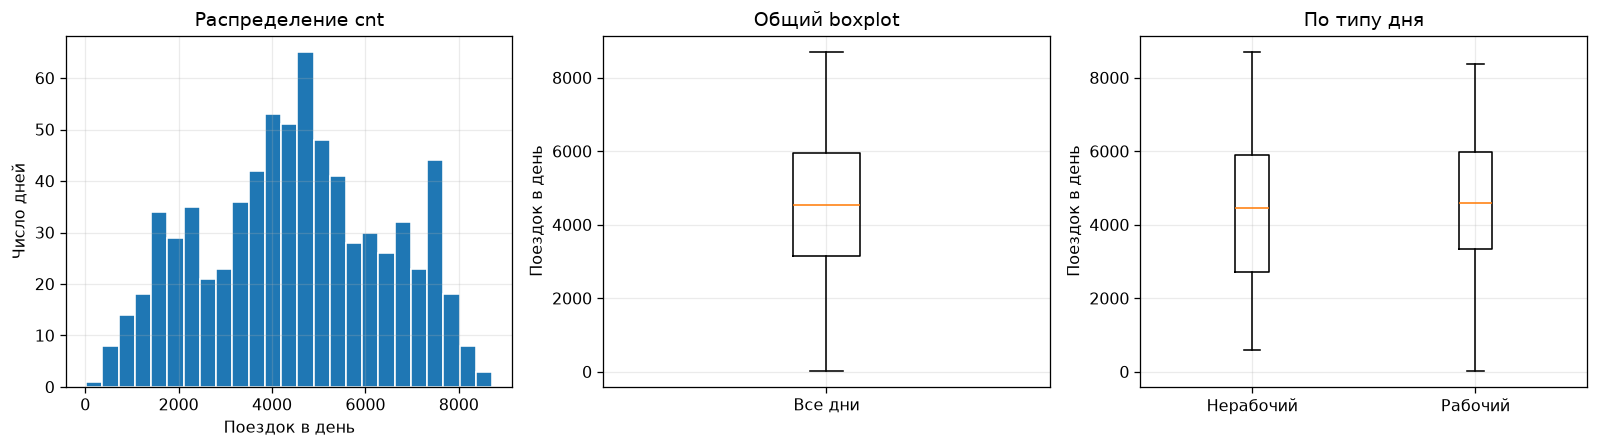

In [4]:
day = pd.read_csv(DATA_DIR / "day.csv", parse_dates=["dteday"])
assert day.shape == (731, 16)
assert (day["dteday"].dt.year == day["yr"] + 2011).all()
audit = pd.DataFrame({
    "dtype": day.dtypes.astype(str),
    "missing": day.isna().sum(),
    "nunique": day.nunique(),
})
print(f"Строк: {len(day)}, полных дубликатов: {day.duplicated().sum()}, пропусков: {day.isna().sum().sum()}")
display(audit)
display(day["cnt"].describe(percentiles=[0.25, 0.50, 0.75]).to_frame("cnt"))
display(day.groupby("workingday")["cnt"].agg(["count", "mean", "median", "std"]))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(day["cnt"], bins=25, edgecolor="white")
axes[0].set(xlabel="Поездок в день", ylabel="Число дней", title="Распределение cnt")
axes[1].boxplot(day["cnt"], tick_labels=["Все дни"])
axes[1].set(ylabel="Поездок в день", title="Общий boxplot")
axes[2].boxplot([day.loc[day["workingday"] == 0, "cnt"],
                 day.loc[day["workingday"] == 1, "cnt"]],
                tick_labels=["Нерабочий", "Рабочий"])
axes[2].set(ylabel="Поездок в день", title="По типу дня")
fig.tight_layout()
plt.show()


## 4. Смещение способа отбора

Весь `day.csv` — известный учебный эталон для демонстрации смещения,
а не неизвестная генеральная совокупность. Для выборки $S$

$$
\operatorname{bias}(S)=\bar x_S-\bar x_{\mathrm{day}}.
$$

Сравните её среднее с тремя выборками размера 90: случайной,
первыми 90 днями и 90 случайными днями июня–августа.


### Ответ: смещение способа отбора

Все 731 наблюдение — известный учебный эталон с
$\bar x_{day}=\mathbf{4504.35}$ поездки/день. Для выборки $S$ здесь
назовём смещением относительно таблицы
$\operatorname{bias}(S)=\bar x_S-\bar x_{day}$; это реализованная разность,
а не теоретическое смещение метода по всем возможным выборкам.
Случайные 90 дней дали среднее $\mathbf{4357.12}$ (разность $-147.23$),
первые 90 дней — $\mathbf{1671.66}$ ($-2832.69$), а 90 случайных
дней июня–августа — $\mathbf{5782.27}$ ($+1277.92$).
Первые дни отражают начало 2011 года, летняя выборка намеренно
перепредставляет сезон; обе плохо оценивают среднее всех дней.
Даже простая случайная выборка без замены остаётся случайно отличной
от полного известного набора.


,Способ,n,Среднее,Разность с полным набором
0,Все 731 день,731,"4,504.3488",0.0000
1,Случайные 90,90,"4,357.1222",-147.2266
2,Первые 90,90,"1,671.6556","-2,832.6933"
3,Летние 90,90,"5,782.2667","1,277.9178"


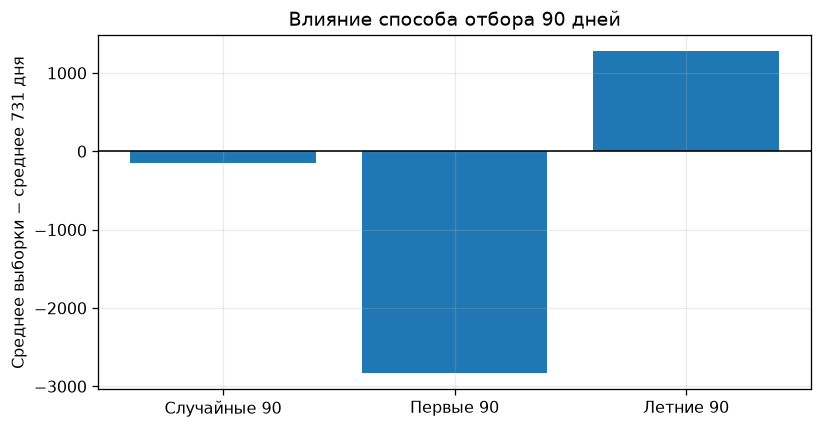

In [5]:
full_mean = day["cnt"].mean()
random_sample = day.sample(n=90, random_state=RANDOM_STATE)
first_90 = day.sort_values("dteday").head(90)
summer_90 = day.loc[day["mnth"].isin([6, 7, 8])].sample(n=90,
                                                        random_state=RANDOM_STATE)
sample_table = pd.DataFrame({
    "Способ": ["Все 731 день", "Случайные 90", "Первые 90", "Летние 90"],
    "n": [len(day), len(random_sample), len(first_90), len(summer_90)],
    "Среднее": [full_mean, random_sample["cnt"].mean(),
                first_90["cnt"].mean(), summer_90["cnt"].mean()],
})
sample_table["Разность с полным набором"] = sample_table["Среднее"] - full_mean
display(sample_table)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(sample_table["Способ"][1:], sample_table["Разность с полным набором"][1:])
ax.axhline(0, color="black", lw=1)
ax.set(ylabel="Среднее выборки − среднее 731 дня",
       title="Влияние способа отбора 90 дней")
plt.show()


## 5. Интервалы, подтверждение и множественные проверки

**Обозначения и модель.** Бутстреп (*bootstrap*) строит 10 000
выборок с возвращением и берёт квантили 0.025 и 0.975 распределения
их средних. Эти интервалы относятся к среднему процесса
сопоставимых дней; временная зависимость и сезонность ограничивают
их i.i.d.-интерпретацию.

Для Welch t-test при сравнении групп $1$ и $0$

$$
t_W=\frac{\bar x_1-\bar x_0}
{\sqrt{s_1^2/n_1+s_0^2/n_0}}.
$$

Welch допускает разные дисперсии, но не устраняет смешение
факторов и автокорреляцию. При $m=100$ нулевых тестах ориентир
ложных находок равен $\operatorname{E}[V]\approx m\alpha=5$; это ожидание,
а не обязательный результат каждого запуска.


### Ответ: интервалы, подтверждение и множественные проверки

Для случайных 90 дней с выборочным $s$ 95%-й t-интервал
$\bar x\pm t_{0.975,89}s/\sqrt{90}$ равен
$\mathbf{[3920.42;\ 4793.83]}$ поездки/день. Percentile bootstrap из
10 000 повторных выборок с возвращением и зерном 42 даёт
$\mathbf{[3920.86;\ 4781.10]}$. Они характеризуют среднее процесса
сопоставимых дней при допущении приблизительно независимых наблюдений;
сезонность и временная зависимость ограничивают это толкование.
Среднее уже полностью наблюдаемой таблицы известно точно.

В 2011 году разведочная разность средних между рабочими и нерабочими
днями составила $\mathbf{61.24}$ поездки. Зафиксировав вопрос, на
2012 году проверяем $H_0:\mu_1-\mu_0=0$ двусторонним Welch t-test.
Для $n_1=250$ и $n_0=116$ разность $\bar x_1-\bar x_0=
\mathbf{456.39}$ поездки/день, $t_W=\mathbf{2.1071}$,
$p=\mathbf{0.03645}$ и 95%-й Welch-интервал
$\mathbf{[29.10;\ 883.69]}$. На уровне 0.05 разность статистически
значима, но её практическая важность зависит от задачи; условия
рабочего дня могут смешиваться с сезоном, погодой, праздниками и трендом.
Welch не устраняет автокорреляцию и не доказывает причинность.

При 100 проверках случайных бинарных групп на всей таблице получено
$\mathbf{10}$ значений $p<0.05$. При истинных нулевых гипотезах
$E[V]\approx100\cdot0.05=5$, но конкретный запуск не обязан дать 5.
Выбор случайно значимой группы после перебора — «ошибка снайпера»;
эти метки не представляют реальные факторы спроса.


In [6]:
# 4.1. Интервалы для случайных 90 дней
sample_values = random_sample["cnt"].to_numpy()
sample_mean = sample_values.mean()
sample_se = sample_values.std(ddof=1) / np.sqrt(len(sample_values))
t_ci = stats.t.interval(0.95, df=len(sample_values) - 1,
                        loc=sample_mean, scale=sample_se)
bootstrap_rng = np.random.default_rng(RANDOM_STATE)
bootstrap_means = bootstrap_rng.choice(sample_values,
                                       size=(10_000, len(sample_values)),
                                       replace=True).mean(axis=1)
bootstrap_ci = np.quantile(bootstrap_means, [0.025, 0.975])
display(pd.DataFrame({
    "Интервал": ["t-интервал 95%", "Percentile bootstrap 95%"],
    "Нижняя граница": [t_ci[0], bootstrap_ci[0]],
    "Верхняя граница": [t_ci[1], bootstrap_ci[1]],
}))

# 4.2. Исследование на 2011 году, подтверждение на 2012 году
def workingday_groups(frame):
    return (frame.loc[frame["workingday"] == 1, "cnt"],
            frame.loc[frame["workingday"] == 0, "cnt"])

explore_work, explore_other = workingday_groups(day.loc[day["yr"] == 0])
explore_difference = explore_work.mean() - explore_other.mean()
confirm_work, confirm_other = workingday_groups(day.loc[day["yr"] == 1])
welch_result = stats.ttest_ind(confirm_work, confirm_other, equal_var=False)
mean_difference = confirm_work.mean() - confirm_other.mean()
v1 = confirm_work.var(ddof=1) / len(confirm_work)
v0 = confirm_other.var(ddof=1) / len(confirm_other)
welch_se = np.sqrt(v1 + v0)
welch_df = (v1 + v0) ** 2 / (v1 ** 2 / (len(confirm_work) - 1)
                              + v0 ** 2 / (len(confirm_other) - 1))
welch_ci = stats.t.interval(0.95, df=welch_df,
                            loc=mean_difference, scale=welch_se)
print(f"Разведочная разность 2011: {explore_difference:.2f}")
print(f"2012: n1={len(confirm_work)}, n0={len(confirm_other)}")
print(f"Разность: {mean_difference:.2f}; Welch t={welch_result.statistic:.4f}; p={welch_result.pvalue:.5f}")
print(f"95%-й Welch-интервал: [{welch_ci[0]:.2f}; {welch_ci[1]:.2f}]")

# 4.3. Сто случайных проверок нулевых групп
group_rng = np.random.default_rng(RANDOM_STATE)
p_values = []
for _ in range(100):
    labels = group_rng.integers(0, 2, size=len(day))
    p_values.append(stats.ttest_ind(day.loc[labels == 1, "cnt"],
                                    day.loc[labels == 0, "cnt"],
                                    equal_var=False).pvalue)
false_discoveries = int(np.sum(np.array(p_values) < 0.05))
print(f"Случайных p < 0.05: {false_discoveries} из 100; ориентир E[V] ≈ 5")


,Интервал,Нижняя граница,Верхняя граница
0,t-интервал 95%,"3,920.4159","4,793.8286"
1,Percentile bootstrap 95%,"3,920.8578","4,781.0958"


Разведочная разность 2011: 61.24
2012: n1=250, n0=116
Разность: 456.39; Welch t=2.1071; p=0.03645
95%-й Welch-интервал: [29.10; 883.69]
Случайных p < 0.05: 10 из 100; ориентир E[V] ≈ 5


## Итоговая модельная карточка вывода

В Markdown-ячейке ниже кратко заполните: вопрос, единицу наблюдения,
способ отбора, статистику/тест, оценку неопределённости, результат и
ограничения. Обязательно разделите статистическую значимость,
практический размер эффекта и причинность.


### Итоговая карточка статистического вывода

**Вопрос.** Различался ли средний дневной спрос на велопрокат между
рабочими и нерабочими днями в 2012 году?

**Данные и отбор.** Единица наблюдения — день (`day.csv`); гипотеза
намечена после разведочного анализа 2011 года, затем проверена на
366 днях 2012 года без пересмотра вопроса.

**Метод и неопределённость.** Разность средних и двусторонний Welch
t-test с 95%-м Welch-интервалом. На 2012 году рабочие дни имели в
среднем на $\mathbf{456.39}$ поездки больше; $p=\mathbf{0.03645}$,
95%-й интервал $\mathbf{[29.10;\ 883.69]}$ поездки/день.

**Вывод и пределы.** Нулевая разность отвергается при $\alpha=0.05$,
но размер эффекта и широкая неопределённость требуют отдельной
практической оценки. Дни последовательно зависимы; погода, сезон,
праздники и тренд могут смешивать сравнение. Поэтому результат не
устанавливает причинный эффект статуса рабочего дня. При множественном
переборе гипотез одиночное $p<0.05$ особенно ненадёжно.
